
# CI7340 CW1 — Dataset Understanding and Data Quality Assessment

**Group 8 | Applied Data Programming | Research Report and Visualisation**

**Team Members:**

    Aruna D Mahagamage (K2600143)
    Baba Isham Sally (K2703532)
    K G Nilanga Nayanajith Abeysekara (K2703512)
    Mihiri Thilakaratne (K2703522)

**Scope:** This notebook covers dataset understanding, the essential CW1 data-quality checks, and one shared analytical dataset. Research questions are completed separately.



## 1. Environment Setup

### 1.1 Install Required Libraries

**Aim:** Install the Python libraries required for data analysis, data cleaning, visualisation and statistical testing.

**Libraries:**
- `pandas` - Working with datasets and DataFrames.
- `numpy` - Numerical calculations.
- `matplotlib` - Creating charts and graphs.
- `seaborn` - Creating statistical visualisations.
- `scipy` - Performing statistical tests.
- `statsmodels` - Performing advanced statistical analysis.

**Option 1: Windows CMD or PowerShell**

Open Command Prompt or PowerShell and run:

```bash
py -m pip install pandas numpy matplotlib seaborn scipy statsmodels
```

**Option 2: Jupyter Notebook**

Run the following command in a Jupyter **Code cell**:

```python
%pip install pandas numpy matplotlib seaborn scipy statsmodels
```

**Note:**
- `%pip` works inside Jupyter Notebook, not in Windows CMD or PowerShell.
- Libraries only need to be installed once per Python environment.
- If a library is already installed, there is no need to reinstall it.
- If a library is installed but cannot be imported, check that Jupyter is using the correct Python environment.

**Decision:** Use Pandas and NumPy for dataset understanding and data quality assessment. The visualisation and statistical libraries will be used when required for the research questions.



### 1.2 Import Required Libraries

The following libraries are imported for data analysis,
data cleaning, visualisation and statistical testing.

- Pandas and NumPy are used for data preparation.
- Matplotlib and Seaborn are used for visualisations.
- SciPy and Statsmodels are available for statistical tests.

Some libraries may only be used in later research questions.



In [1]:
# Import required libraries

# Data analysis
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Statistical analysis
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

## 2. Dataset Understanding
**Aim:** Load the original CSV and understand its columns, types and records.

**Finding:** The original dataset contains 508,106 offence rows and 30 columns. One incident may have multiple offence rows.

**Decision:** Keep the original data unchanged. Work on copies.

In [2]:
# Load the original dataset from the project root folder
dataset_path = "dataset_coursework1-1.csv"

df_raw = pd.read_csv(dataset_path, low_memory=False)

# Check the number of rows and columns
print("Dataset shape:", df_raw.shape)

# Display the first five records
print("\nFirst five records:")
display(df_raw.head())

# Display column names
print("\nColumn names:")
print(df_raw.columns.tolist())

# Display data types and missing-value information
print("\nDataset information:")
df_raw.info()

Dataset shape: (508106, 30)

First five records:


,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,...,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
0,201590757,9108,260040147,NaN,09/14/2026 08:44:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
1,201590749,2901,260040333,09/14/2026 07:46:02 PM,09/14/2026 07:46:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,702,13000.0,NaN,MIDDLEBROOK,NaN,RD,39.18138,-77.2695,5D,"(39.1814, -77.2695)"
2,201590742,9199,260040311,09/14/2026 06:01:40 PM,09/14/2026 06:01:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
3,201590754,9108,260040316,NaN,09/14/2026 06:00:00 PM,09/14/2026 07:00:00 PM,90Z,1,Crime Against Society,All Other Offenses,...,425,200.0,NaN,PARAMOUNT PARK,NaN,DR,39.15876,-77.2224,6D,"(39.1588, -77.2224)"
4,201590766,9199,260040314,09/14/2026 05:52:52 PM,09/14/2026 05:52:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,140,10100.0,NaN,NEW HAMPSHIRE,NaN,AVE,39.02039,-76.9766,3D,"(39.0204, -76.9766)"



Column names:
['Incident ID', 'Offence Code', 'CR Number', 'Dispatch Date / Time', 'Start_Date_Time', 'End_Date_Time', 'NIBRS Code', 'Victims', 'Crime Name1', 'Crime Name2', 'Crime Name3', 'Police District Name', 'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place', 'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix', 'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude', 'Police District Number', 'Location']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 508106 entries, 0 to 508105
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Incident ID             508106 non-null  int64  
 1   Offence Code            508106 non-null  str    
 2   CR Number               508106 non-null  int64  
 3   Dispatch Date / Time    434701 non-null  str    
 4   Start_Date_Time         508106 non-null  str    
 5   End_Date_Time           225662 non-null  str  

### 2.1 Check column types
**Aim:** Identify which columns need type conversion.

**Decision:** Convert dates in a working copy. Keep identifiers as identifiers, not numerical measures.

In [3]:
type_summary = pd.DataFrame({
    "Data Type": df_raw.dtypes,
    "Non-Missing": df_raw.notna().sum(),
    "Unique Values": df_raw.nunique(dropna=True)
})
display(type_summary)

,Data Type,Non-Missing,Unique Values
Incident ID,int64,508106,467601
Offence Code,str,508106,360
CR Number,int64,508106,467534
Dispatch Date / Time,str,434701,397963
Start_Date_Time,str,508106,372500
End_Date_Time,str,225662,157941
NIBRS Code,str,508106,54
Victims,int64,508106,10
Crime Name1,str,508106,4
Crime Name2,str,508106,54


## 3. Data Quality Assessment

### 3.1 Missing Values

**Aim:** Find which fields have missing data.

**Method:** Use `isna()` to count missing values and calculate their percentages for each column.

**Finding:** 13 columns have at least one missing value. `End_Date_Time` is about 55.59% missing, and `Dispatch Date / Time` is about 14.45% missing.

**Decision:** Do not remove rows just because optional fields are missing. Handle missing data according to each research question.

In [4]:
missing_summary = pd.DataFrame({
    "Missing Count": df_raw.isna().sum(),
    "Missing %": (df_raw.isna().mean() * 100).round(2)
})
display(missing_summary.sort_values("Missing %", ascending=False))
print("Columns with missing values:", (missing_summary["Missing Count"] > 0).sum())

,Missing Count,Missing %
Street Suffix,501176,98.64
Street Prefix,485545,95.56
End_Date_Time,282444,55.59
Dispatch Date / Time,73405,14.45
Block Address,39804,7.83
Address Number,39661,7.81
State,9509,1.87
Zip Code,3474,0.68
Street Type,1856,0.37
Police District Name,1542,0.30


Columns with missing values: 13


### 3.2 Blank and Whitespace-Only Values

**Aim:** Check for blank or whitespace-only values that may not be identified by `isna()`.

**Method:** Check all text columns for empty strings and values containing only spaces.

**Finding:** No additional blank or whitespace-only values were found in the text columns.

**Decision:** No additional cleaning is required for blank text values.



In [5]:
# Check blank and whitespace-only values in all text columns

text_columns = df_raw.select_dtypes(
    include=["object", "string"]
).columns

blank_counts = {}

for column in text_columns:
    blank_counts[column] = (
        df_raw[column]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    )

# Create a summary table
blank_summary = pd.Series(
    blank_counts,
    name="Blank Text Count"
)

# Display columns with blank values
display(
    blank_summary[blank_summary > 0]
    .sort_values(ascending=False)
)

# Display total blank text values
print("Total blank text values:", blank_summary.sum())

Series([], Name: Blank Text Count, dtype: int64)

Total blank text values: 0


### 3.3 Duplicates and repeated Incident IDs
**Aim:** Distinguish duplicate rows from valid multiple offences in one incident.

**Finding:** No exact duplicate rows were found. The source has 467,601 unique Incident IDs.

**Decision:** Do not remove repeated Incident IDs.

In [6]:
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Unique Incident IDs:", df_raw["Incident ID"].nunique())
incident_sizes = df_raw.groupby("Incident ID").size()
print("Incidents with multiple offence rows:", (incident_sizes > 1).sum())
print("Maximum offence rows in one incident:", incident_sizes.max())
print("Incidents with multiple offence codes:",
      (df_raw.groupby("Incident ID")["Offence Code"].nunique() > 1).sum())

Exact duplicate rows: 0
Unique Incident IDs: 467601
Incidents with multiple offence rows: 33749
Maximum offence rows in one incident: 9
Incidents with multiple offence codes: 33749


### 3.4 Incident ID and CR Number
**Aim:** Check whether these identifiers represent the same groups.

**Finding:** 67 CR Numbers are linked to multiple Incident IDs; no Incident ID has multiple CR Numbers.

**Decision:** Use `Incident ID` when counting unique incidents. Do not assume `CR Number` is interchangeable.

In [7]:
cr_per_incident = df_raw.groupby("Incident ID")["CR Number"].nunique()
incidents_per_cr = df_raw.groupby("CR Number")["Incident ID"].nunique()
print("Incident IDs with multiple CR Numbers:", (cr_per_incident > 1).sum())
print("CR Numbers with multiple Incident IDs:", (incidents_per_cr > 1).sum())
print("Unique CR Numbers:", df_raw["CR Number"].nunique())

Incident IDs with multiple CR Numbers: 0
CR Numbers with multiple Incident IDs: 67
Unique CR Numbers: 467534


### 3.5 Date and time validation
**Aim:** Check date conversion, date order and the coursework period (1 July 2016–10 September 2026).

**Finding:** 8,418 records have an end time earlier than their start time. 228 records fall outside the study period.

**Decision:** Keep a flag for questionable time order; exclude outside-period records only from the shared study dataset.

In [8]:
df_dates = df_raw.copy()
date_columns = ["Start_Date_Time", "End_Date_Time", "Dispatch Date / Time"]
for column in date_columns:
    before = df_dates[column].notna().sum()
    df_dates[column] = pd.to_datetime(
        df_dates[column], format="%m/%d/%Y %I:%M:%S %p", errors="coerce"
    )
    after = df_dates[column].notna().sum()
    print(column, "parsing failures:", before - after)

bad_time = (df_dates["End_Date_Time"].notna()
            & df_dates["Start_Date_Time"].notna()
            & (df_dates["End_Date_Time"] < df_dates["Start_Date_Time"]))

study_start = pd.Timestamp("2016-07-01")
study_end = pd.Timestamp("2026-09-10 23:59:59")
outside_period = (df_dates["Start_Date_Time"].isna()
                  | (df_dates["Start_Date_Time"] < study_start)
                  | (df_dates["Start_Date_Time"] > study_end))
print("End before start:", bad_time.sum())
print("Outside study period or missing start time:", outside_period.sum())

Start_Date_Time parsing failures: 0
End_Date_Time parsing failures: 0
Dispatch Date / Time parsing failures: 0
End before start: 8418
Outside study period or missing start time: 228


### 3.6 Coordinates
**Aim:** Identify unusable coordinates for mapping.

**Finding:** 24,648 records have at least one zero coordinate.

**Decision:** Flag them; do not remove them from non-map analyses.

In [9]:
latitude = pd.to_numeric(df_raw["Latitude"], errors="coerce")
longitude = pd.to_numeric(df_raw["Longitude"], errors="coerce")
zero_coordinates = latitude.eq(0) | longitude.eq(0)
print("Zero-coordinate rows:", zero_coordinates.sum())
print("Missing latitude:", latitude.isna().sum())
print("Missing longitude:", longitude.isna().sum())
print("Latitude outside -90 to 90:", ((latitude < -90) | (latitude > 90)).sum())
print("Longitude outside -180 to 180:", ((longitude < -180) | (longitude > 180)).sum())

Zero-coordinate rows: 24648
Missing latitude: 0
Missing longitude: 0
Latitude outside -90 to 90: 0
Longitude outside -180 to 180: 0


### 3.7 Victims and Category Values

**Aim:** Identify unusual numeric values and inconsistent labels.

**Method:** Check `Victims` using descriptive statistics and the IQR method. Review the number of City and State labels.

**Finding:** The `Victims` median is 1 and the maximum is 22. The IQR is 0, so the method flags 9,060 records with values greater than 1 as potential outliers. These may be genuine incidents with multiple victims.

**Decision:** Do not automatically remove high `Victims` values or guess corrections for category labels.

In [10]:
victims = pd.to_numeric(df_raw["Victims"], errors="coerce")
display(victims.describe())
q1 = victims.quantile(0.25)
q3 = victims.quantile(0.75)
iqr = q3 - q1
outliers = (victims < q1 - 1.5 * iqr) | (victims > q3 + 1.5 * iqr)
print("Victims IQR:", iqr)
print("Potential IQR outliers:", outliers.sum())
print("Different City labels:", df_raw["City"].nunique())
print("Different State labels:", df_raw["State"].nunique())
display(df_raw["State"].value_counts(dropna=False).head(10))

count    508106.000000
mean          1.021832
std           0.184835
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          22.000000
Name: Victims, dtype: float64

Victims IQR: 0.0
Potential IQR outliers: 9060
Different City labels: 314
Different State labels: 12


State
MD     498230
NaN      9509
16        224
DC        121
VA         12
ME          2
MS          2
7           1
ND          1
17          1
Name: count, dtype: int64

### 3.8 Compare missing-data methods
**Aim:** Decide whether removing missing rows is suitable.

**Finding:** Dropping rows missing any original field would remove all in-period rows.

**Decision:** Keep missing data in shared files; handle it separately for each research question.

In [11]:
df_working = df_dates.copy()
df_working["flag_zero_coordinates"] = zero_coordinates
df_working["flag_end_before_start"] = bad_time
df_working["flag_outside_study_period"] = outside_period

df_study = df_working.loc[~df_working["flag_outside_study_period"]].copy()

original_columns = df_raw.columns.tolist()
essential_columns = ["Incident ID", "Offence Code", "Crime Name2", "Start_Date_Time"]

comparison = pd.DataFrame({
    "Method": ["Drop any missing field", "Drop missing essential fields", "Keep missing values"],
    "Rows Kept": [
        len(df_study.dropna(subset=original_columns)),
        len(df_study.dropna(subset=essential_columns)),
        len(df_study)
    ]
})
comparison["Retained %"] = (comparison["Rows Kept"] / len(df_study) * 100).round(2)
display(comparison)
print("Raw rows:", len(df_raw))
print("In-scope rows:", len(df_study))
print("Rows excluded:", len(df_raw) - len(df_study))

,Method,Rows Kept,Retained %
0,Drop any missing field,0,0.0
1,Drop missing essential fields,507878,100.0
2,Keep missing values,507878,100.0


Raw rows: 508106
In-scope rows: 507878
Rows excluded: 228


## 4. Shared dataset for group research
**Aim:** Give all members one consistent starting dataset.

**Method:** Keep in-period offence records; use parsed dates, three quality flags and explicit column renaming.

**Decision:** Preserve missing values and repeated Incident IDs. Members do research-specific cleaning on their own copies.

In [12]:
# Explicitly rename the eight known source column variants.
column_mapping = {
    "Offence Code": "Offense Code",
    "Dispatch Date / Time": "Dispatch Date/Time",
    "Start_Date_Time": "Start Date/Time",
    "End_Date_Time": "End Date/Time",
    "Crime Name1": "Crime Name 1",
    "Crime Name2": "Crime Name 2",
    "Crime Name3": "Crime Name 3",
    "Location": "Geolocation"
}

assert all(column in df_study.columns for column in column_mapping)
df_group = df_study.rename(columns=column_mapping).copy()
print("Raw dataset:", df_raw.shape)
print("Shared study dataset:", df_group.shape)
print("Duplicate column names:", df_group.columns.duplicated().sum())
print("Unique in-scope Incident IDs:", df_group["Incident ID"].nunique())
display(df_group.head())

Raw dataset: (508106, 30)
Shared study dataset: (507878, 33)
Duplicate column names: 0
Unique in-scope Incident IDs: 467384


,Incident ID,Offense Code,CR Number,Dispatch Date/Time,Start Date/Time,End Date/Time,NIBRS Code,Victims,Crime Name 1,Crime Name 2,...,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Geolocation,flag_zero_coordinates,flag_end_before_start,flag_outside_study_period
228,201590316,5016,260039762,2026-09-10 23:29:11,2026-09-10 23:29:00,2026-09-10 23:29:00,90Z,1,Crime Against Society,All Other Offenses,...,RESEARCH,NaN,BLV,39.10499,-77.1904,6D,"(39.105, -77.1904)",False,False,False
229,201590311,9201,260039761,2026-09-10 23:16:12,2026-09-10 23:16:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,TUCKERMAN,NaN,LA,39.04871,-77.1841,1D,"(39.0487, -77.1841)",False,False,False
230,201590312,2203,260039760,2026-09-10 22:50:41,2026-09-10 22:50:00,NaT,220,1,Crime Against Property,Burglary/Breaking and Entering,...,WISCONSIN,NaN,AVE,38.99123,-77.0956,2D,"(38.9912, -77.0956)",False,False,False
231,201590312,2901,260039760,2026-09-10 22:50:41,2026-09-10 22:50:00,NaT,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,WISCONSIN,NaN,AVE,38.99123,-77.0956,2D,"(38.9912, -77.0956)",False,False,False
232,201590307,9113,260039757,2026-09-10 22:33:43,2026-09-10 22:33:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,FALLING WATER,NaN,CIR,39.18591,-77.2658,5D,"(39.1859, -77.2658)",False,False,False


### 4.1 Final Dataset Validation

**Aim:** Check that the shared dataset is ready for research analysis.

**Method:** Check the dataset size, column names, missing start dates and study period.

**Finding:** The shared dataset contains 507,878 rows and 33 columns. All validation checks passed.

**Decision:** Use this dataset as the common starting point after group approval.

In [13]:
# Basic shared-dataset checks
assert df_raw.shape == (508106, 30), "Original file differs from assessed source"
assert df_group.shape == (507878, 33), "Study-period dataset differs from expected"
assert df_group.columns.is_unique
assert df_group["Start Date/Time"].notna().all()
assert df_group["flag_outside_study_period"].sum() == 0
assert len(df_raw) - len(df_group) == 228
print("Shared data validation passed.")

Shared data validation passed.


### 4.2 Save the Shared Dataset

**Aim:** Save one common dataset for all group members.

**Method:** Export the validated DataFrame as a Parquet file.

**Decision:** All members will use the same approved dataset version for their research questions.

In [14]:
# Run these lines after your group approves the dataset.
from pathlib import Path
Path("data/processed").mkdir(parents=True, exist_ok=True)
df_group.to_parquet("data/processed/cw1_shared_v1.parquet", index=False)
print("Shared dataset saved.")

Shared dataset saved.


## 5. Data Quality Summary

| Issue | Group decision |
|---|---|
| Missing values | Keep; handle per question |
| Repeated Incident IDs | Keep valid offence records |
| End-before-start timestamps | Flag; do not guess corrections |
| Out-of-period records | Exclude from shared study dataset (228 rows) |
| Zero coordinates | Flag; filter for mapping only |
| Victims outliers | Keep pending case-specific evidence |
| Unusual city/place/state labels | Do not automatically replace |

**Next step:** Each member loads the approved shared dataset into a separate research notebook. Research-question analysis is **not included** in this notebook.

# CI7340 CW1 — Research Question Development Guide

**Group 8 | Applied Data Programming**

Follow these steps after the shared dataset has been approved and Section 4.2 has been completed.

## 1. Update the Project

Open PowerShell or VS Code Terminal.

Go to your `MSC-AI-CW1` project folder.

```bash
git switch main
git pull origin main
```

**Note:** Make sure `dataset_coursework1-1.csv` and the approved `cw1_shared_v1.parquet` dataset are available.

## 2. Create Your Branch

Each member must create a separate branch from `main`.

```bash
git switch -c feature/aruna-rqs
```

Suggested branch names:

- Aruna: `feature/aruna-rqs`
- Isham: `feature/isham-rqs`
- Nilanga: `feature/nilanga-rqs`
- Mihiri: `feature/mihiri-rqs`

**Decision:** Do not develop research questions directly on `main`.

## 3. Create Your Research Notebook

Create a separate notebook inside the `notebooks` folder.

Example: `notebooks/Aruna_RQs.ipynb`

### First Markdown Cell

```markdown
# CI7340 CW1 — Research Questions

**Group:** 8

**Member:** Aruna D Mahagamage

**Dataset:** Montgomery County Crime Dataset

**Data Version:** cw1_shared_v1.parquet
```

### First Python Code Cell

```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the approved shared dataset
df_shared = pd.read_parquet(
    "data/processed/cw1_shared_v1.parquet"
)

# Create a working copy
df_rq = df_shared.copy()

print("Dataset shape:", df_rq.shape)
```

**Expected dataset shape:** `(507878, 33)`

**Note:** These paths assume JupyterLab is running from the `MSC-AI-CW1` root folder.

**Decision:** Do not modify the shared dataset. Use a separate DataFrame for your analysis.

## 4. Follow the Standard Research Question Format

Use the following Markdown structure for every research question.

### 4.1 Research Question

```markdown
## RQ1 — Research Topic

**Research Question:** Write your research question.

**Aim:** Explain what you want to investigate.

**Method:** Explain which columns and analytical methods will be used.
```

### 4.2 Data Preparation

Select the required columns and prepare your analysis DataFrame.

Example:

```python
df_analysis = df_rq[
    ["Incident ID", "Crime Name 2", "Police District Name"]
].copy()

display(df_analysis.head())
```

### 4.3 Findings

After running the analysis, document the actual results.

```markdown
### Findings

**Finding:** Describe the important results.

**Decision:** Explain what the results indicate.
```

### 4.4 Hypothesis Testing (If Required)

```markdown
### Hypothesis Testing

**H0:** Write the null hypothesis.

**H1:** Write the alternative hypothesis.

**Method:** State the statistical test.

**Result:** Record the test statistic and p-value, where applicable.

**Decision:** Reject or fail to reject H0.

**Interpretation:** Explain what the result means.
```

Only use statistical tests that are suitable for the research question.

### 4.5 Visualisations

Each research question must include **two meaningful visualisations**.

```markdown
### Visualisation 1

**Aim:** Explain what the chart shows.

**Finding:** Describe the main result.

### Visualisation 2

**Aim:** Explain what the chart shows.

**Finding:** Describe the main result.
```

Graphs must have clear titles, axis labels and appropriate legends when needed.

### 4.6 Conclusion

```markdown
### Conclusion

**Conclusion:** Summarise the answer to the research question.

**Limitations:** Mention important limitations.
```

**Important:** Use actual results from your analysis. Do not assume findings before running the code.

## 5. Save and Commit Changes

After completing your research questions, save your notebook.

Check your changes:

```bash
git status
```

Add your notebook:

```bash
git add notebooks/Aruna_RQs.ipynb
```

Commit your changes:

```bash
git commit -m "feat(cw1): add Aruna research question analysis"
```

Push your branch:

```bash
git push -u origin feature/aruna-rqs
```

Replace the member name and branch name with your own.

## 6. Create a Pull Request

Open the GitHub repository.

1. Select your feature branch.
2. Click **Compare & pull request**.
3. Add a short description.
4. Request a review from the group.

### Suggested PR Description

**Summary:** Completed my assigned CW1 research questions.

**Changes:**
- Added data preparation and analysis.
- Added two visualisations per research question.
- Documented findings and conclusions.
- Used the approved shared dataset.

**Validation:**
- Notebook runs without errors.
- Results and graphs have been checked.
- Shared dataset was not modified.

**Review:** Please review the analysis before merging.

## 7. Merge to Main

After the Pull Request is reviewed and approved:

1. Open the Pull Request on GitHub.
2. Click **Merge pull request**.
3. Confirm the merge.
4. Delete the feature branch if no longer needed.

Update your local `main` branch:

```bash
git switch main
git pull origin main
```

**Decision:** Merge changes through reviewed Pull Requests.

## 8. Prepare the Final Notebook

After all research notebooks have been merged into `main`, combine them into:

`CW1_Final.ipynb`

Follow this order:

1. Environment Setup
2. Dataset Understanding
3. Data Quality Assessment
4. Shared Dataset Preparation
5. Research Questions 1–10
6. Findings and Conclusion

Avoid duplicate imports, repeated preparation steps and conflicting variable names.

### Final Validation

- Restart the Jupyter kernel and run all cells.
- Confirm all 10 research questions are included.
- Confirm all 20 visualisations are displayed.
- Check that the analysis runs without errors.
- Verify that results match the individual notebooks.
- Ensure the approved shared dataset remains unchanged.

## Final Workflow

**Pull main → Create branch → Create notebook → Load shared dataset → Complete research questions → Commit → Push → Pull Request → Review → Merge → Combine final notebook**

**Important:** All members must use the same approved dataset and follow the same Markdown structure.

## 6. Setup for RQ1 and RQ2

### 6.1 Libraries

**Aim:** Use the libraries needed for the two research questions.

**Method:** Pandas and NumPy help us prepare the data. Matplotlib is used for graphs, and SciPy is used for the hypothesis tests. These libraries are already included in the shared notebook imports.

If a library is missing, run this in a Jupyter **Code cell**:

```python
%pip install matplotlib scipy
```

Or use PowerShell:

```powershell
py -3.14 -m pip install matplotlib scipy
```

Make sure Jupyter uses the same Python installation. After installing a missing package, restart the kernel.

**Decision:** We will use the libraries already included in the coursework notebook. No extra packages are needed for these questions.

### 6.2 Libraries used in the analysis

**Aim:** Make it clear which libraries are used for our graphs and statistical tests.

**Method:** Matplotlib creates the graphs. SciPy provides the Chi-Square tests. The imports below can be run again without changing the earlier setup.

In [15]:
# Libraries used for the research questions
import matplotlib.pyplot as plt
from scipy import stats

print("Research libraries are ready.")

Research libraries are ready.


## 7. RQ1 — Crime Categories Recorded Together

**Research Question:** Which crime types are commonly recorded together in the same incident, and how does the association between selected drug-related crimes differ across police districts?

**Aim:** Find crime categories that appear together and check whether the selected drug-related pair has the same relationship in every police district.

**Method:** Use `Incident ID`, `Crime Name 2` and `Police District Name`. Count each crime category once per incident. Then calculate counts, Lift and Odds Ratios and run the hypothesis tests.

**Data:** Work from `df_group` without changing it.

In [16]:
# Create a separate dataset for this research question
rq1_data = df_group[[
    "Incident ID", "Crime Name 2", "Police District Name"
]].copy()

# Count each category once for each incident
incident_crimes = rq1_data[["Incident ID", "Crime Name 2"]].drop_duplicates()
incident_categories = incident_crimes.groupby("Incident ID")["Crime Name 2"].unique()

number_of_categories = incident_categories.map(len)
multi_category = incident_categories[number_of_categories > 1]

print("Total incidents:", len(incident_categories))
print("Incidents with multiple crime categories:", len(multi_category))
display(incident_crimes.head())

Total incidents: 467384
Incidents with multiple crime categories: 31127


,Incident ID,Crime Name 2
228,201590316,All Other Offenses
229,201590311,All Other Offenses
230,201590312,Burglary/Breaking and Entering
231,201590312,Destruction/Damage/Vandalism of Property
232,201590307,All Other Offenses


### 7.1 Find Common Crime Pairs

**Aim:** Find out which two crime categories are recorded together most often.

**Method:** Take incidents with more than one crime category, create the category pairs and count them.

**Finding:** The table shows the ten most common pairs.

**Decision:** An incident counts once for each pair, even if its category appears on several offence rows.

In [17]:
# Count unique crime-category pairs
crime_pairs = []

for categories in multi_category:
    categories = sorted(categories)
    for i in range(len(categories)):
        for j in range(i + 1, len(categories)):
            crime_pairs.append((categories[i], categories[j]))

pair_counts = pd.Series(crime_pairs).value_counts()

print("Number of different crime pairs:", len(pair_counts))
print("Top 10 common crime pairs:")
display(pair_counts.head(10))

Number of different crime pairs: 535
Top 10 common crime pairs:


(Destruction/Damage/Vandalism of Property, Theft From Motor Vehicle)          2664
(All Other Offenses, Simple Assault)                                          1732
(Drug Equipment Violations, Drug/Narcotic Violations)                         1724
(Destruction/Damage/Vandalism of Property, Simple Assault)                    1594
(Credit Card/Automatic Teller Machine Fraud, Theft From Motor Vehicle)        1184
(Burglary/Breaking and Entering, Destruction/Damage/Vandalism of Property)    1145
(Disorderly Conduct, Simple Assault)                                          1092
(All Other Offenses, Drug/Narcotic Violations)                                1062
(Motor Vehicle Theft, Theft From Motor Vehicle)                               1034
(Drug/Narcotic Violations, Weapon Law Violations)                              901
Name: count, dtype: int64

### 7.2 Calculate Lift

**Aim:** Check whether a frequent pair also has a strong association.

**Method:** Lift compares the observed number of incidents with the number expected if the two categories were independent.

**Finding:** A Lift greater than 1 means the pair appears together more often than expected under independence.

**Decision:** Look at Lift and the incident count together. A rare pair can have a high Lift.

In [18]:
# Calculate Lift for each crime pair
category_counts = incident_crimes["Crime Name 2"].value_counts()
total_incidents = len(incident_categories)

pair_results = []
for pair, together in pair_counts.items():
    category_a, category_b = pair
    count_a = category_counts[category_a]
    count_b = category_counts[category_b]
    expected = count_a * count_b / total_incidents
    lift = together / expected
    pair_results.append({
        "Category A": category_a,
        "Category B": category_b,
        "Together": together,
        "Lift": lift
    })

pair_lift = pd.DataFrame(pair_results)
print("Top 10 pairs by number of incidents:")
display(pair_lift.sort_values("Together", ascending=False).head(10).round(2))

Top 10 pairs by number of incidents:


,Category A,Category B,Together,Lift
0,Destruction/Damage/Vandalism of Property,Theft From Motor Vehicle,2664,0.94
1,All Other Offenses,Simple Assault,1732,0.18
2,Drug Equipment Violations,Drug/Narcotic Violations,1724,9.66
3,Destruction/Damage/Vandalism of Property,Simple Assault,1594,0.63
4,Credit Card/Automatic Teller Machine Fraud,Theft From Motor Vehicle,1184,1.62
5,Burglary/Breaking and Entering,Destruction/Damage/Vandalism of Property,1145,1.16
6,Disorderly Conduct,Simple Assault,1092,1.77
7,All Other Offenses,Drug/Narcotic Violations,1062,0.16
8,Motor Vehicle Theft,Theft From Motor Vehicle,1034,0.65
9,Drug/Narcotic Violations,Weapon Law Violations,901,4.04


### 7.3 Hypothesis Test 1 — Drug-Related Crime Categories

**Aim:** Test whether the selected drug-related categories are associated.

**H0:** Drug Equipment Violations and Drug/Narcotic Violations are independent.

**H1:** The two crime categories are associated.

**Method:** Use a Chi-Square Test of Independence on incident counts. The significance level is 0.05.

**Decision rule:** Reject H0 if the p-value is less than 0.05.

In [19]:
# Build the incident-level contingency table
category_a = "Drug Equipment Violations"
category_b = "Drug/Narcotic Violations"

# Check whether each incident contains the selected categories
incident_crimes["Drug Equipment"] = incident_crimes["Crime Name 2"].eq(category_a)
incident_crimes["Drug/Narcotic"] = incident_crimes["Crime Name 2"].eq(category_b)
incident_flags = incident_crimes.groupby("Incident ID")[[
    "Drug Equipment", "Drug/Narcotic"
]].max()

contingency = pd.crosstab(
    incident_flags["Drug Equipment"],
    incident_flags["Drug/Narcotic"]
)
display(contingency)

chi2, p_value, dof, expected = stats.chi2_contingency(contingency, correction=False)
print("Chi-Square:", round(chi2, 2))
print("Degrees of freedom:", dof)
print("p-value:", "< 1e-300" if p_value == 0 else p_value)
if p_value < 0.05:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

both = int((incident_flags["Drug Equipment"] & incident_flags["Drug/Narcotic"]).sum())
expected_both = (incident_flags["Drug Equipment"].sum()
                 * incident_flags["Drug/Narcotic"].sum() / len(incident_flags))
print("Both categories:", both)
print("Lift:", round(both / expected_both, 2))

Drug/Narcotic,False,True
Drug Equipment,,
False,440353,23757
True,1550,1724


Chi-Square: 14253.46
Degrees of freedom: 1
p-value: < 1e-300
Decision: Reject H0
Both categories: 1724
Lift: 9.66


### 7.4 Compare Police Districts

**Aim:** See whether the relationship between the two drug-related categories changes by district.

**Method:** Take one district value per incident and calculate an Odds Ratio for each district.

**Finding:** The table shows the total incidents, incidents with both categories and the Odds Ratio.

**Decision:** Leave out incidents with a missing district. An Odds Ratio is not a crime rate.

In [20]:
# Create a district-level incident table
incident_district = rq1_data.groupby("Incident ID")["Police District Name"].first()

district_data = incident_flags.join(incident_district).dropna(
    subset=["Police District Name"]
).copy()
district_data["Both"] = (
    district_data["Drug Equipment"] & district_data["Drug/Narcotic"]
)

district_group = district_data.groupby("Police District Name")
district_summary = district_group[[
    "Drug Equipment", "Drug/Narcotic", "Both"
]].sum()
district_summary["Total Incidents"] = district_group.size()

# Prepare the four counts for each district
district_summary["Equipment Only"] = (
    district_summary["Drug Equipment"] - district_summary["Both"]
)
district_summary["Narcotic Only"] = (
    district_summary["Drug/Narcotic"] - district_summary["Both"]
)
district_summary["Neither"] = (
    district_summary["Total Incidents"]
    - district_summary["Both"]
    - district_summary["Equipment Only"]
    - district_summary["Narcotic Only"]
)

# Leave out the small OTHER district group
named_districts = district_summary.drop(index="OTHER", errors="ignore").copy()
named_districts["Odds Ratio"] = (
    named_districts["Both"] * named_districts["Neither"]
) / (
    named_districts["Equipment Only"] * named_districts["Narcotic Only"]
)

print("Incidents with known police district:", len(district_data))
display(named_districts[["Total Incidents", "Both", "Odds Ratio"]].round(2))

Incidents with known police district: 465962


,Total Incidents,Both,Odds Ratio
Police District Name,,,
BETHESDA,68083,132,46.81
GERMANTOWN,59287,214,18.82
MONTGOMERY VILLAGE,78209,443,23.23
ROCKVILLE,64128,203,32.09
SILVER SPRING,96745,396,15.65
TAKOMA PARK,13606,36,20.05
WHEATON,85890,297,13.19


### 7.5 Visualisation 1 — Odds Ratios by District

**Aim:** Compare the selected crime-pair association across police districts.

**Method:** Draw a horizontal bar chart using the district Odds Ratios.

**Finding:** The chart makes it easier to see which districts have higher or lower Odds Ratios.

**Decision:** Use the statistical test in Section 7.6 before deciding whether the differences are significant.

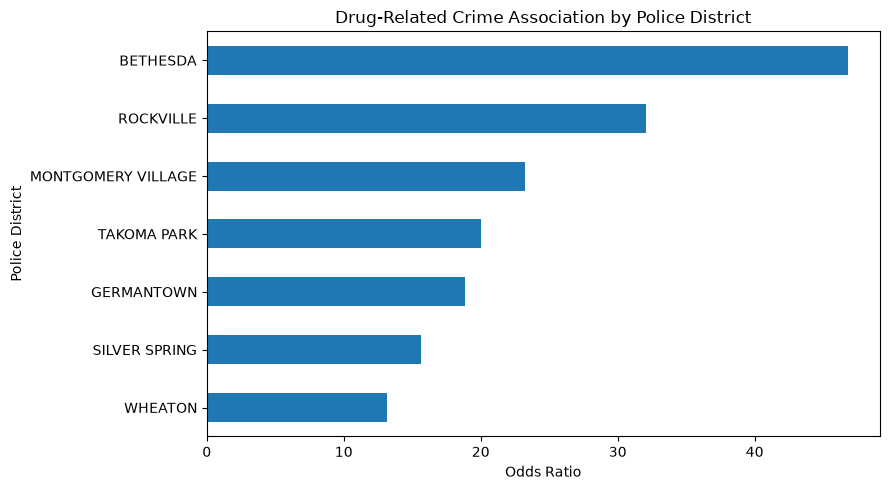

In [21]:
# Plot the district Odds Ratios
ax = named_districts["Odds Ratio"].sort_values().plot(
    kind="barh", figsize=(9, 5),
    title="Drug-Related Crime Association by Police District",
    xlabel="Odds Ratio", ylabel="Police District"
)
plt.tight_layout()
plt.show()

### 7.6 Hypothesis Test 2 — District Differences

**Aim:** Check whether the Odds Ratios differ across the seven named districts.

**H0:** The selected crime-pair association has the same population Odds Ratio across districts.

**H1:** At least one district has a different population Odds Ratio.

**Method:** Use an approximate comparison of the log Odds Ratios at the 0.05 significance level.

**Decision rule:** Reject H0 if the p-value is less than 0.05.

**Note:** This is an approximate test. It does not tell us exactly which districts differ.

In [22]:
# Approximate test of equal Odds Ratios
# Check that all counts are greater than zero
cells = named_districts[[
    "Both", "Equipment Only", "Narcotic Only", "Neither"
]]
assert (cells > 0).all().all(), "Some districts contain zero counts"

a = cells["Both"]
b = cells["Equipment Only"]
c = cells["Narcotic Only"]
d = cells["Neither"]

log_or = np.log((a * d) / (b * c))
variance = 1/a + 1/b + 1/c + 1/d
weight = 1 / variance
average = (weight * log_or).sum() / weight.sum()
q_statistic = (weight * (log_or - average) ** 2).sum()
df_test = len(cells) - 1
p_district = stats.chi2.sf(q_statistic, df_test)

print("District test statistic:", round(q_statistic, 2))
print("Degrees of freedom:", df_test)
print("p-value:", p_district)
if p_district < 0.05:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

District test statistic: 98.44
Degrees of freedom: 6
p-value: 5.300476025283088e-19
Decision: Reject H0


### 7.7 Visualisation 2 — Frequency and Lift

**Aim:** Compare how common a crime pair is with how strongly its categories are associated.

**Method:** Draw a scatter plot of incident counts against Lift. Include pairs reported together in at least 200 incidents.

**Finding:** The graph helps us see whether frequent pairs also have high Lift values.

**Decision:** The 200-incident limit keeps the graph readable, but it leaves out less common pairs.

Pairs shown in graph: 46


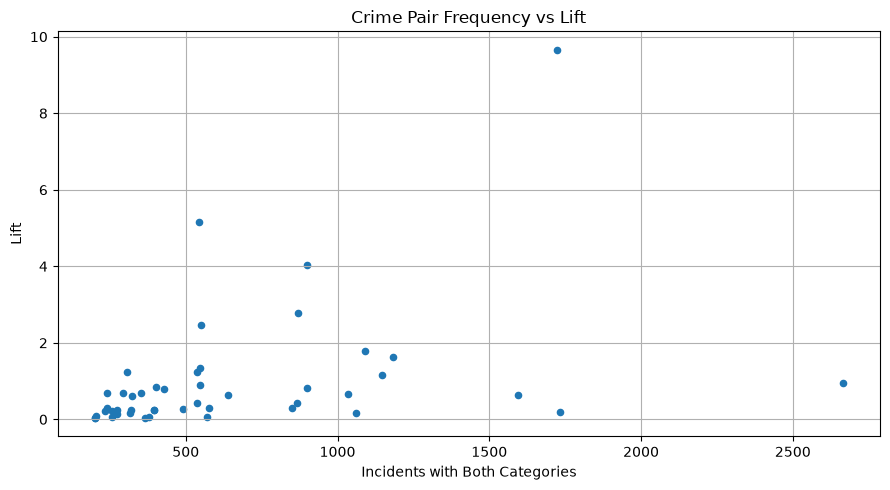

In [23]:
# Plot frequency versus Lift
scatter_data = pair_lift[pair_lift["Together"] >= 200].copy()
print("Pairs shown in graph:", len(scatter_data))

ax = scatter_data.plot(
    kind="scatter", x="Together", y="Lift", figsize=(9, 5),
    title="Crime Pair Frequency vs Lift",
    xlabel="Incidents with Both Categories", ylabel="Lift", grid=True
)
plt.tight_layout()
plt.show()

### 7.8 RQ1 — Findings and Conclusion

**Finding:** Drug Equipment Violations and Drug/Narcotic Violations appeared together in 1,724 incidents. Their Lift was about 9.66. This means they were recorded together more often than expected if the categories were independent.

**Hypothesis Test 1:** The Chi-Square statistic was about 14,253.46, with p < 0.05. We reject H0 and find evidence that the categories are associated.

**Hypothesis Test 2:** The district comparison statistic was about 98.44, with p < 0.05. We reject H0. The strength of the association was not the same across all seven districts.

**Conclusion:** These two drug-related crime categories often appear in the same incident, but the relationship differs between districts.

**Limitations:** The data contains reported offences only. A relationship does not mean that one offence causes another. Missing district information and differences in reporting may affect the comparison. The district test is approximate.

**Decision:** Use the two figures and the main results to answer RQ1 in the group report.

## 8. RQ2 — Multiple-Victim Incidents by Location Type

**Research Question:** How does the proportion of incidents involving multiple victims differ between location types?

**Aim:** Compare the share of incidents with more than one recorded victim across different locations.

**Method:** Use `Incident ID`, `Place` and `Victims`. Compare Residence, Street, Parking and Retail using counts, percentages, two graphs and a Chi-Square test.

**Data:** Use a separate working copy of `df_group` so the approved dataset stays unchanged.

### 8.1 Prepare One Row per Incident

**Aim:** Avoid counting one incident several times.

**Method:** Check if the same Incident ID has different Place or Victims values. Keep only incidents with one consistent place and victim value.

**Finding:** The output shows how many incidents have conflicting values and how many we can use.

**Decision:** Leave conflicting incidents out of RQ2 instead of choosing a value without evidence. This does not remove them from the shared dataset.

In [24]:
# Select the columns needed for this question
rq2_data = df_group[["Incident ID", "Place", "Victims"]].copy()

# Check whether an incident has different recorded values
rq2_checks = rq2_data.groupby("Incident ID").agg({
    "Place": ["first", "nunique"],
    "Victims": ["first", "nunique"]
})
rq2_checks.columns = ["Place", "Place Count", "Victims", "Victims Count"]

# Keep incidents with consistent place and victim values
rq2_incidents = rq2_checks.loc[
    (rq2_checks["Place Count"] == 1)
    & (rq2_checks["Victims Count"] == 1)
].copy()

print("All incidents:", len(rq2_checks))
print("Incidents with different places:", (rq2_checks["Place Count"] > 1).sum())
print("Incidents with different victim counts:", (rq2_checks["Victims Count"] > 1).sum())
print("Incidents kept for RQ2:", len(rq2_incidents))

All incidents: 467384
Incidents with different places: 8374
Incidents with different victim counts: 1681
Incidents kept for RQ2: 457716


### 8.2 Select Location Types

**Aim:** Keep the location comparison easy to understand.

**Method:** Group place descriptions into Residence, Street, Parking and Retail. The other place types are not used in this comparison.

**Finding:** The output shows how many incidents belong to our four groups.

**Decision:** Report that this analysis covers only these selected location types.

In [25]:
# Group the main location types
rq2_incidents["Location Type"] = "Other"

for name in ["Residence", "Street", "Parking", "Retail"]:
    rq2_incidents.loc[
        rq2_incidents["Place"].str.startswith(name, na=False),
        "Location Type"
    ] = name

rq2_selected = rq2_incidents.loc[
    rq2_incidents["Location Type"] != "Other"
].copy()

# More than one recorded victim is counted as multiple victims
rq2_selected["Multiple Victims"] = rq2_selected["Victims"] > 1

print("Incidents in the four location types:", len(rq2_selected))
print("Other locations not compared:", len(rq2_incidents) - len(rq2_selected))
display(rq2_selected[["Place", "Victims", "Location Type", "Multiple Victims"]].head())

Incidents in the four location types: 338249
Other locations not compared: 119467


,Place,Victims,Location Type,Multiple Victims
Incident ID,,,,
201087096,Residence - Apartment/Condo,1,Residence,False
201087102,Parking Lot - County,1,Parking,False
201087104,Street - Commercial,1,Street,False
201087108,Residence - Apartment/Condo,1,Residence,False
201087119,Parking Garage - Other,1,Parking,False


### 8.3 Calculate Multiple-Victim Percentages

**Aim:** Compare the proportion of incidents with more than one victim.

**Method:** Count incidents with more than one recorded victim and divide by the total number of incidents in each location group.

**Finding:** The table gives the incident counts and percentages for each group.

**Decision:** Use percentages for comparison because the location groups have different numbers of incidents.

In [26]:
# Count incidents for each location type
rq2_table = pd.crosstab(
    rq2_selected["Location Type"], rq2_selected["Multiple Victims"]
)
rq2_table = rq2_table.reindex(columns=[False, True], fill_value=0)
rq2_table.columns = ["Single Victim", "Multiple Victims"]
rq2_table["Total Incidents"] = rq2_table.sum(axis=1)
rq2_table["Multiple Victim %"] = (
    rq2_table["Multiple Victims"] / rq2_table["Total Incidents"] * 100
).round(2)

print("Incidents and percentages by location type:")
display(rq2_table.sort_values("Multiple Victim %", ascending=False))

Incidents and percentages by location type:


,Single Victim,Multiple Victims,Total Incidents,Multiple Victim %
Location Type,,,,
Residence,141861,4401,146262,3.01
Parking,58993,612,59605,1.03
Street,91287,947,92234,1.03
Retail,39995,153,40148,0.38


### 8.4 Visualisation 1 — Multiple-Victim Percentages

**Aim:** See which location group has the highest percentage of multiple-victim incidents.

**Method:** Make a bar chart of the percentages from Section 8.3.

**Finding:** Residence has the highest percentage, and Retail has the lowest.

**Decision:** Compare percentages rather than using the total number of cases alone.

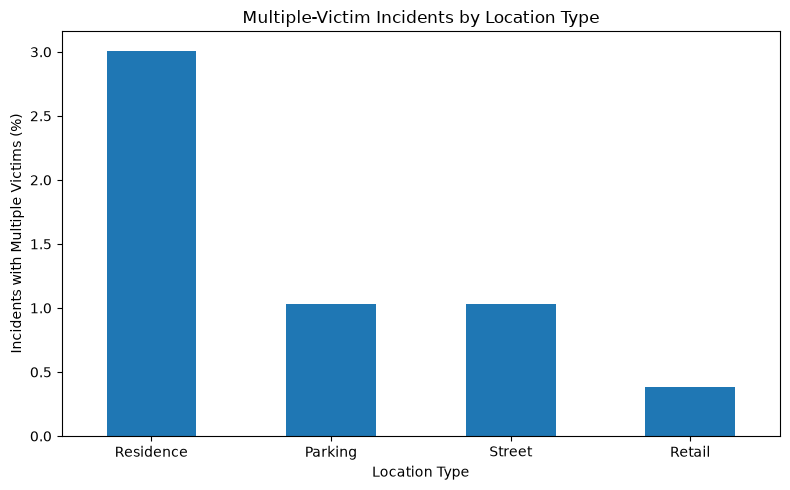

In [27]:
# Bar chart of multiple-victim percentages
rq2_percentages = rq2_table["Multiple Victim %"].sort_values(ascending=False)

ax = rq2_percentages.plot(
    kind="bar", figsize=(8, 5),
    title="Multiple-Victim Incidents by Location Type",
    xlabel="Location Type", ylabel="Incidents with Multiple Victims (%)",
    rot=0
)
plt.tight_layout()
plt.show()

### 8.5 Hypothesis Test — Location Type and Multiple Victims

**Aim:** Test whether multiple-victim status is related to location type.

**H0:** Location type and multiple-victim status are independent.

**H1:** Location type and multiple-victim status are associated.

**Method:** Use a Chi-Square Test of Independence with the four location groups and two victim groups. The significance level is 0.05.

**Decision rule:** Reject H0 when the p-value is less than 0.05. An association does not prove that location causes more victims.

In [28]:
# Chi-Square test using the incident counts
rq2_counts = rq2_table[["Single Victim", "Multiple Victims"]]
chi2_rq2, p_rq2, dof_rq2, expected_rq2 = stats.chi2_contingency(rq2_counts)

print("Chi-Square:", round(chi2_rq2, 2))
print("Degrees of freedom:", dof_rq2)
print("p-value:", "< 0.001" if p_rq2 < 0.001 else round(p_rq2, 4))

if p_rq2 < 0.05:
    print("Decision: Reject H0. Location type and multiple-victim status are associated.")
else:
    print("Decision: Fail to reject H0. Not enough evidence of an association.")

Chi-Square: 2171.68
Degrees of freedom: 3
p-value: < 0.001
Decision: Reject H0. Location type and multiple-victim status are associated.


### 8.6 Visualisation 2 — Incident Counts

**Aim:** Show the number of incidents behind the percentages.

**Method:** Use a grouped bar chart to compare incidents with one or fewer recorded victims and incidents with more than one victim.

**Finding:** Some location groups have many more incidents than others.

**Decision:** Use this chart together with the percentage chart. Counts alone are not a fair way to compare groups of different sizes.

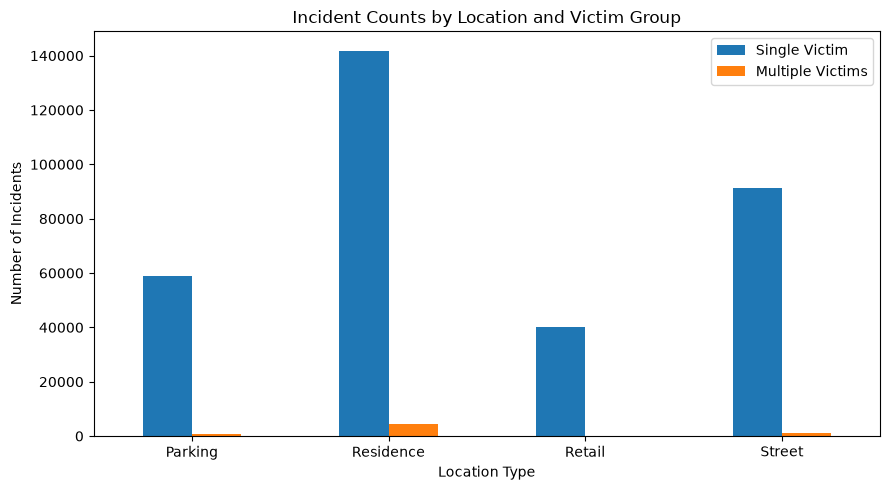

In [29]:
# Grouped bar chart of incident counts
ax = rq2_counts.plot(
    kind="bar", figsize=(9, 5),
    title="Incident Counts by Location and Victim Group",
    xlabel="Location Type", ylabel="Number of Incidents", rot=0
)
plt.tight_layout()
plt.show()

### 8.7 RQ2 — Findings and Conclusion

**Finding:** Residence had the highest percentage of multiple-victim incidents (3.01%). Parking and Street were about 1.03% each, and Retail was 0.38%.

**Hypothesis Test:** The Chi-Square statistic was about 2,171.68 (df = 3, p < 0.001). We reject H0. There is evidence of an association between location type and multiple-victim status.

**Conclusion:** Multiple-victim percentages are different across these four location groups. This result does not show that the location causes the difference.

**Limitations:** This study uses reported incidents. We left out incidents with conflicting Place or Victims values and did not compare every location type. The number of victims is based on what was recorded in the dataset.

**Decision:** Include the two charts and the Chi-Square result in the CW1 report. Do not treat these percentages as a person's risk of becoming a victim.